# Task 2 – HAM vs. SPAM: Vocabulary Differences

Which words are distinctively associated with HAM or SPAM?

## Method: Log-Odds Ratio

For each word, I compute:

$$\text{log-odds}(w) = \log \frac{P(w \mid \text{SPAM})}{P(w \mid \text{HAM})}$$

- **Positive** → word leans towards SPAM
- **Negative** → word leans towards HAM
- **Laplace smoothing** (add-one) prevents division by zero for unseen words

Unlike raw counts, log-odds corrects for class imbalance (86 % HAM / 14 % SPAM).

In [5]:
from IPython.display import display
from pathlib import Path

from sms_analysis import load_dataset
from sms_analysis.analysis import log_odds_ratio
from sms_analysis.visualization import plot_ham_spam_comparison, save_figure

DATASET = Path("../assignment/3D8026C4.zip/SMSSpamCollection")
OUTPUTS = Path("outputs")

dataset = load_dataset(DATASET)
ham_texts  = [m.text for m in dataset.ham]
spam_texts = [m.text for m in dataset.spam]

In [6]:
TOP_N = 50

df = log_odds_ratio(ham_texts, spam_texts, top_n=TOP_N)

print("Top SPAM words:")
print(df[df.leaning == "spam"][["word", "log_odds", "spam_count"]].to_string(index=False))
print("\nTop HAM words:")
print(df[df.leaning == "ham"][["word", "log_odds", "ham_count"]].to_string(index=False))

Top SPAM words:
       word  log_odds  spam_count
      claim  5.574949         113
      prize  5.382045          93
       150p  5.028405          65
       tone  4.949625          60
 guaranteed  4.770576          50
         cs  4.645413          44
    awarded  4.502312          38
  token_url  4.403577         105
     150ppm  4.394099          34
   ringtone  4.304487          31
      entry  4.134588          26
      tones  4.134588          26
 collection  4.134588          26
        mob  4.096847          25
     weekly  4.057626          24
      valid  4.057626          24
        10p  4.057626          24
   national  3.974245          22
        sae  3.929793          21
   vouchers  3.929793          21
      bonus  3.929793          21
         uk  3.906804          42
       poly  3.834483          19
unsubscribe  3.783190          18
       land  3.783190          18
      12hrs  3.729122          17
        opt  3.729122          17
    expires  3.729122          1

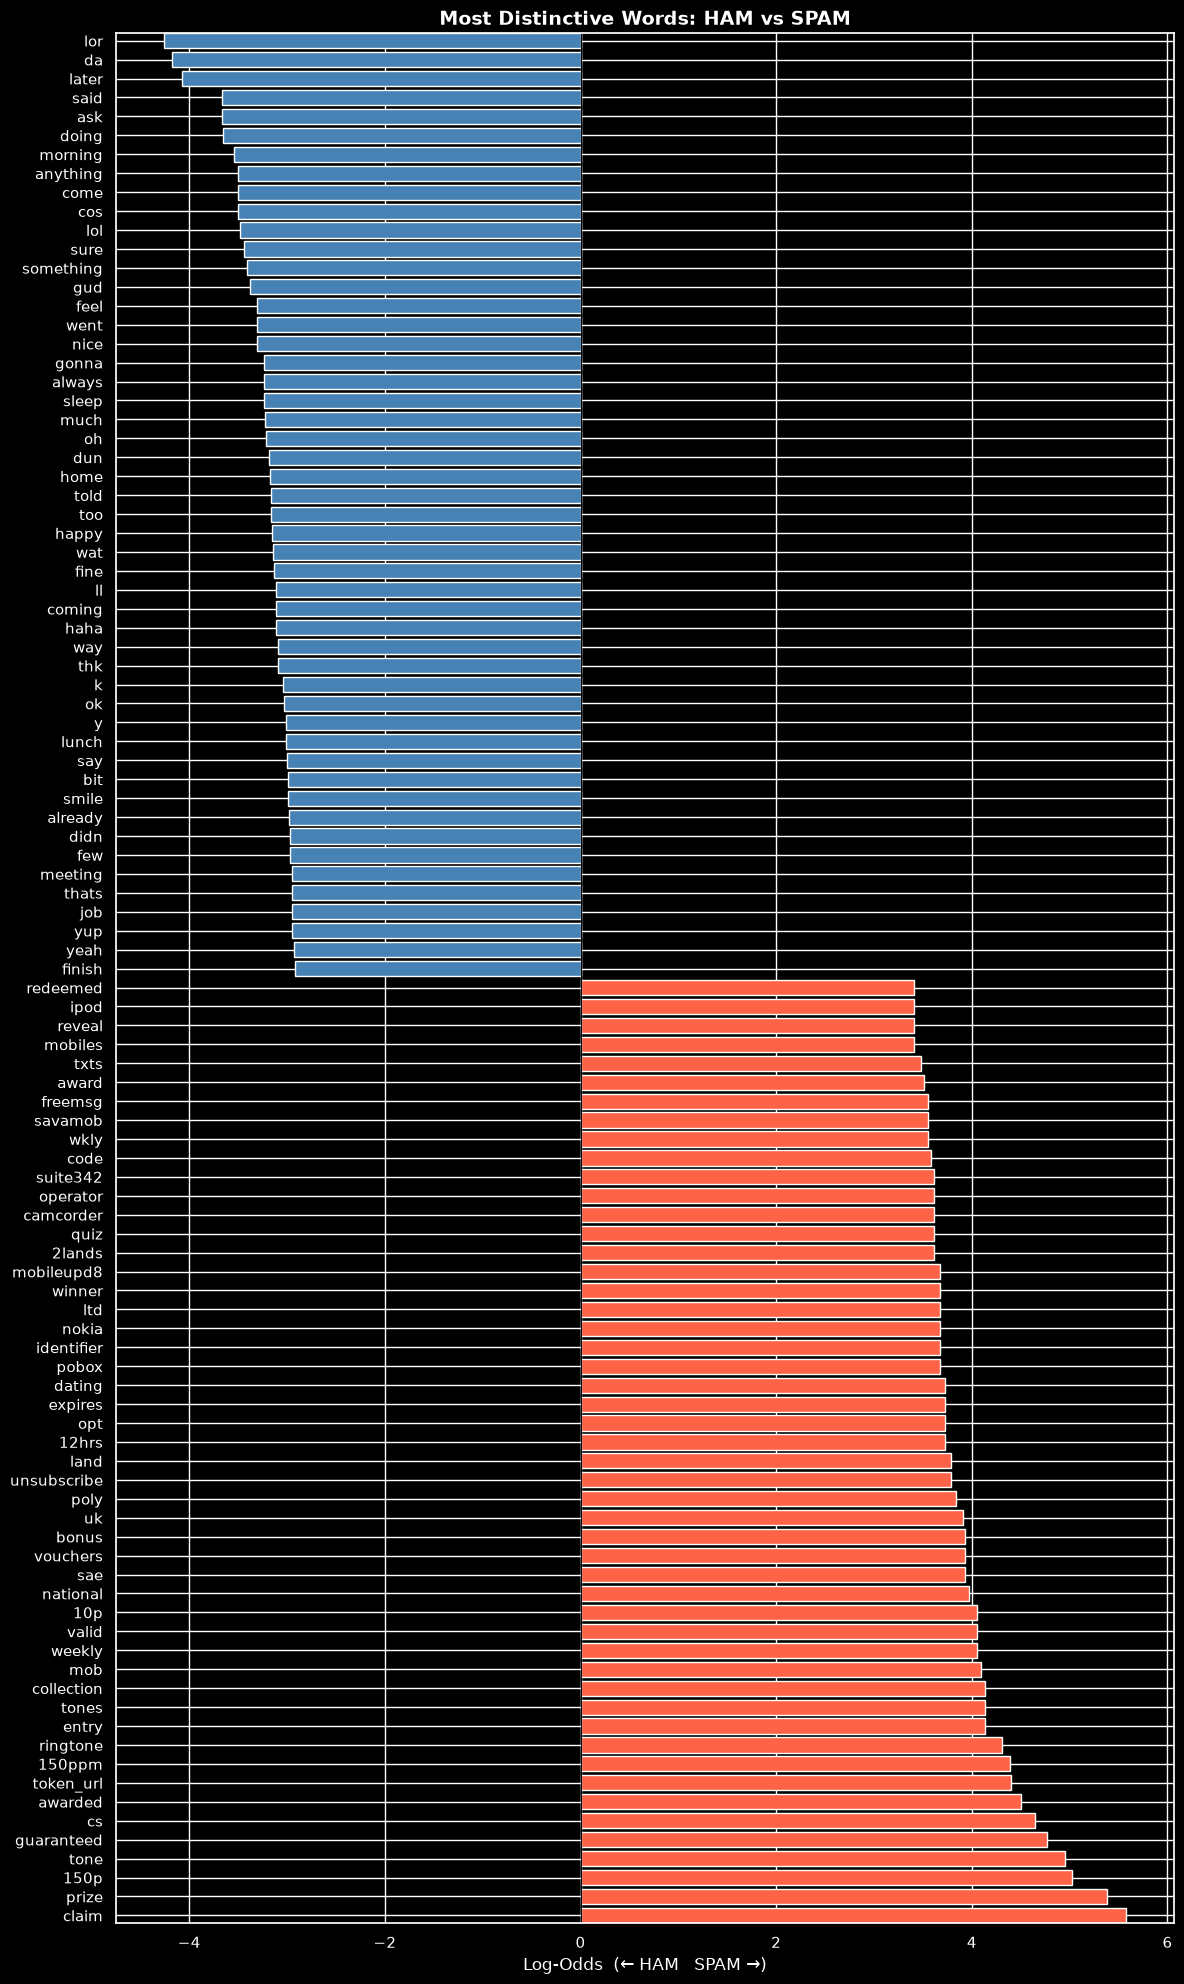

In [8]:
FIG_HEIGHT = 20  # inches; auto = len(df) * 0.35

fig = plot_ham_spam_comparison(df, fig_height=FIG_HEIGHT)
display(fig)
save_figure(fig, OUTPUTS / "02_ham_vs_spam_log_odds.png")

## Observations

**Strongly SPAM-leaning words** reveal the characteristic language of commercial/malicious SMS:
- Action triggers: `claim`, `win`, `prize`, `free`, `urgent`
- Contact channels: `call`, `txt`, `mobile`, `token_url`
- Financial bait: `cash`, `award`, `£`, `guaranteed`

**Strongly HAM-leaning words** reflect natural conversational language:
- Personal pronouns and informality: `im`, `ur`, `wat`, `da`
- Relational terms: `home`, `morning`, `dinner`, `later`
- SMS-specific abbreviations not adopted by spammers

The asymmetry is striking: SPAM vocabulary is highly formulaic and marketer-driven,
while HAM vocabulary is varied and personal. This is why even simple linear models
achieve very high classification accuracy on this dataset.